In [1]:
import sys; sys.path.append("..")
import json, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from src.features import get_splits, make_preprocessor
from src.evaluation import make_cv
from src.business import realized_net, expected_benefit, gains_table

X_train, X_test, y_train, y_test = get_splits("../data/raw/telco_churn.csv")
params = json.load(open("../models/xgb_best_params.json"))

pipe = Pipeline([("pre", make_preprocessor()),
                 ("clf", XGBClassifier(**params, eval_metric="logloss",
                                       tree_method="hist", random_state=42, n_jobs=1))])
oof = cross_val_predict(pipe, X_train, y_train, cv=make_cv(),
                        method="predict_proba", n_jobs=-1)[:, 1]

print("OOF ROC-AUC %.4f | PR-AUC %.4f" % (roc_auc_score(y_train, oof),
                                          average_precision_score(y_train, oof)))
print("Brier score: model %.4f vs always-predict-the-average %.4f" % (
    brier_score_loss(y_train, oof),
    brier_score_loss(y_train, np.full(len(y_train), y_train.mean()))))

OOF ROC-AUC 0.8498 | PR-AUC 0.6670
Brier score: model 0.1335 vs always-predict-the-average 0.1949


   mean_predicted  actual_churn
0           0.017         0.016
1           0.030         0.011
2           0.052         0.043
3           0.096         0.105
4           0.155         0.130
5           0.237         0.240
6           0.329         0.319
7           0.435         0.442
8           0.569         0.590
9           0.732         0.759


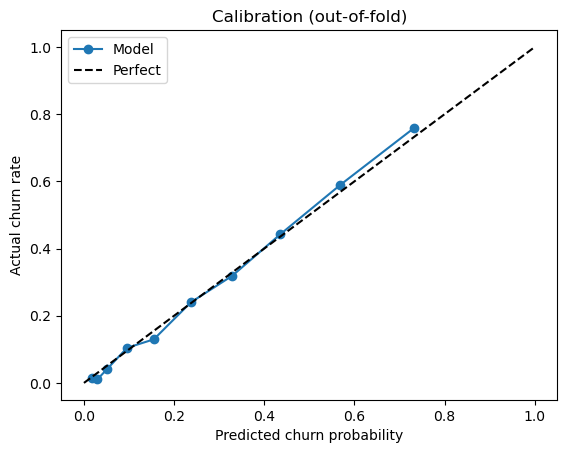

In [2]:
frac, mean_p = calibration_curve(y_train, oof, n_bins=10, strategy="quantile")
print(pd.DataFrame({"mean_predicted": mean_p.round(3), "actual_churn": frac.round(3)}))

plt.plot(mean_p, frac, "o-", label="Model"); plt.plot([0, 1], [0, 1], "k--", label="Perfect")
plt.xlabel("Predicted churn probability"); plt.ylabel("Actual churn rate"); plt.legend()
plt.title("Calibration (out-of-fold)")
plt.savefig("../reports/figures/calibration.png", dpi=150, bbox_inches="tight"); plt.show()

        customers  churners  avg_pred  churn_rate   lift  cum_capture
decile                                                               
1             563       427     0.732       0.758  2.858        0.286
2             563       333     0.569       0.591  2.229        0.508
3             564       249     0.435       0.441  1.664        0.675
4             563       180     0.329       0.320  1.205        0.795
5             564       135     0.237       0.239  0.902        0.886
6             563        73     0.155       0.130  0.489        0.934
7             563        59     0.096       0.105  0.395        0.974
8             564        24     0.052       0.043  0.160        0.990
9             563         6     0.030       0.011  0.040        0.994
10            564         9     0.017       0.016  0.060        1.000


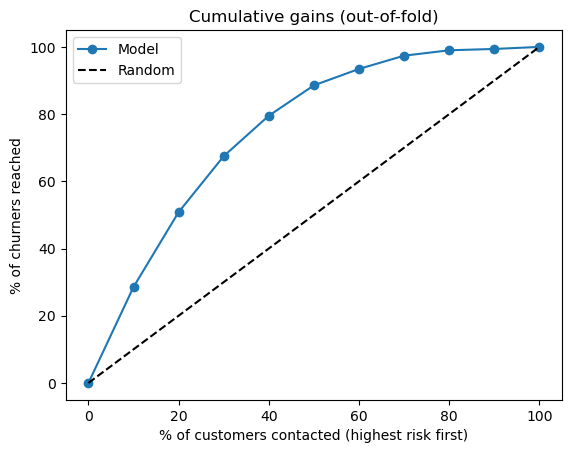

In [3]:
g = gains_table(y_train, oof)
print(g.round(3))

x = np.r_[0, np.arange(1, 11) * 10]; yv = np.r_[0, g["cum_capture"].values * 100]
plt.plot(x, yv, "o-", label="Model"); plt.plot([0, 100], [0, 100], "k--", label="Random")
plt.xlabel("% of customers contacted (highest risk first)"); plt.ylabel("% of churners reached")
plt.legend(); plt.title("Cumulative gains (out-of-fold)")
plt.savefig("../reports/figures/cumulative_gains.png", dpi=150, bbox_inches="tight"); plt.show()

In [4]:
# ===== ASSUMPTIONS (illustrative, not real company data) =====
SAVE_RATE  = 0.25   # share of contacted would-be churners that a retention offer saves
OFFER_COST = 50     # $ cost per contacted customer (discount, call, etc.)
# Value of a saved customer = 12 months of their MonthlyCharges (revenue, not margin)
# =============================================================
monthly = X_train["MonthlyCharges"].values
rows = [("Contact nobody", 0, 0.0)]

everyone = np.ones(len(y_train), bool)
rows.append(("Contact everyone", everyone.sum(),
             realized_net(y_train, monthly, everyone, SAVE_RATE, OFFER_COST)))

c05 = oof >= 0.5
rows.append(("Threshold 0.5", c05.sum(),
             realized_net(y_train, monthly, c05, SAVE_RATE, OFFER_COST)))

grid = np.linspace(0.05, 0.9, 86)
vals = [realized_net(y_train, monthly, oof >= t, SAVE_RATE, OFFER_COST) for t in grid]
best_t = grid[int(np.argmax(vals))]
rows.append((f"Best global threshold ({best_t:.2f})", (oof >= best_t).sum(), max(vals)))

rule = expected_benefit(oof, monthly, SAVE_RATE, OFFER_COST) > 0
rows.append(("Expected-benefit rule (> 0)", rule.sum(),
             realized_net(y_train, monthly, rule, SAVE_RATE, OFFER_COST)))

pd.DataFrame(rows, columns=["strategy", "contacted", "net_dollars"]).round(0)

,strategy,contacted,net_dollars
0,Contact nobody,0,0.0
1,Contact everyone,5634,54048.0
2,Threshold 0.5,1122,126096.0
3,Best global threshold (0.19),2818,162846.0
4,Expected-benefit rule (> 0),2357,170966.0


In [5]:
for s in [0.10, 0.25, 0.40]:
    out = []
    for c in [25, 50, 100]:
        m = expected_benefit(oof, monthly, s, c) > 0
        out.append("cost $%d: net $%d (%d contacted)" % (
            c, realized_net(y_train, monthly, m, s, c), m.sum()))
    print("save rate %.2f | " % s + " | ".join(out))

save rate 0.10 | cost $25: net $57702 (2046 contacted) | cost $50: net $21938 (1060 contacted) | cost $100: net $154 (7 contacted)
save rate 0.25 | cost $25: net $238042 (3096 contacted) | cost $50: net $170966 (2357 contacted) | cost $100: net $82078 (1389 contacted)
save rate 0.40 | cost $25: net $431877 (3665 contacted) | cost $50: net $350076 (2872 contacted) | cost $100: net $230809 (2046 contacted)
